# Fail case: a kinetic constant carried over from another simulator

*Forum thread: [Help with k_kin in SMA isotherm](https://forum.cadet-web.de/t/help-with-k-kin-in-sma-isotherm/908)*

A user wanted to reproduce a CEX load-wash-elute run from GoSilico in CADET.
GoSilico reported four SMA numbers:

| | |
|---|---|
| Equilibrium (SMA) | $k_{eq} = 7 \cdot 10^{-7}$ |
| Kinetic (SMA) | $k_{kin} = 1.8 \cdot 10^{-8}$ |
| Charge (SMA) | $\nu = 10.11$ |
| Shielding (SMA) | $\sigma = 0$ |

GoSilico writes the kinetic SMA with the rate constant on the left,

$$ k_{kin}\,\frac{\mathrm{d}q_i}{\mathrm{d}t} \;=\; k_{eq,i}\,\bar{q}^{\,\nu_i} c_{p,i} \;-\; c_{salt}^{\,\nu_i} q_i , $$

whereas CADET puts the two rate constants on the right,

$$ \frac{\mathrm{d}q_i}{\mathrm{d}t} \;=\; k_{a,i}\,\bar{q}^{\,\nu_i} c_{p,i} \;-\; k_{d,i}\,c_{salt}^{\,\nu_i} q_i . $$

Dividing the first equation by $k_{kin}$ gives the obvious translation

$$ k_a = \frac{k_{eq}}{k_{kin}} = 38.9, \qquad k_d = \frac{1}{k_{kin}} = 5.6 \cdot 10^{7} . $$

That translation is algebraically correct. The simulation fails anyway.
Switching `IS_KINETIC` off makes the same model run.

This notebook reproduces the failure, finds out what actually breaks, and then
asks the question the thread never settled: **is $k_{kin}$ a useful knob for
the stiffness of this problem?**

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from cadet import Cadet

from utility import setting_forum908_SMA_kkin as case
from utility import stiffness_metrics as sm

# CADET-Core v6.0.0a5 pre-release. Point this at your own installation.
CADET_PATH = Path(
    r"C:\Users\jmbr\Desktop\CADET_compiled"
    r"\master8_post6a5withConsInitFixAndCSTRparInterface_b580377\aRELEASE"
)

WORK = Path("data") / "forum908"
WORK.mkdir(parents=True, exist_ok=True)

In [2]:
def simulate(label, quiet=False, **kwargs):
    """Run one variant of the case and return its integrator metrics.

    Returns None if the simulation failed; the error is printed unless
    `quiet` is set.
    """
    simulation = Cadet(install_path=CADET_PATH)
    simulation.root = case.get_model(**kwargs)
    simulation.filename = str(WORK / (label.replace(" ", "_") + ".h5"))

    try:
        return sm.run_and_measure(simulation, label=label)
    except RuntimeError as error:
        if not quiet:
            print(str(error).strip().splitlines()[0])
        return None


def outlet_of(label):
    """Read the column outlet of a run that has already been simulated."""
    loaded = Cadet(install_path=CADET_PATH)
    loaded.filename = str(WORK / (label.replace(" ", "_") + ".h5"))
    loaded.load_from_file()
    return (loaded.root.output.solution.solution_times,
            loaded.root.output.solution.unit_000.solution_outlet)

## 1. The failure

Everything below is the setting exactly as posted, see
`utility/setting_forum908_SMA_kkin.py`: a lumped rate model with pores, two
components (salt and one protein), 713 s load, wash, and a salt gradient from
10 to 336 mol m$^{-3}$.

In [3]:
baseline = simulate("baseline")

Simulation 'baseline' failed: SOLVER ERROR: Error in IDASolve: IDA_ERR_FAIL at t = 713.220000


`IDA_ERR_FAIL` at $t = 713.22$ s, and the step size at that moment is
$6 \cdot 10^{-14}$ s. Two things are worth reading out of that message before
touching anything:

- **713.22 s is not an arbitrary time.** It is the first section transition,
  where the protein feed is switched off and the wash begins. The first 713 s
  integrate without trouble.
- **`h` has collapsed to its minimum.** The integrator did not give up
  because it ran out of steps, it gave up because it could not pass its local
  error test at *any* step size.

The log also reports `Residual has NAN or infinite value in unit 0`. So the
model equations themselves return something that is not a number, and the
solver is only the messenger.

## 2. What makes it run?

Before theorising, collect evidence. Each row below changes exactly one thing.

In [4]:
variants = {
    "baseline": {},
    "is_kinetic = False": dict(is_kinetic=False),
    "init_step_size = 1e-15": dict(init_step_size=1e-15),
    "max_errtest_fail = 10": dict(max_errtest_fail=10),
    "max_newton_iter = 100": dict(max_newton_iter=100),
    "abstol = 1e-6": dict(abstol=1e-6),
    "abstol = 1e-10": dict(abstol=1e-10),
    "nu = 10 (integer)": dict(nu=10.0),
    "ncol = 20": dict(ncol=20),
    "ncol = 200": dict(ncol=200),
    "no protein in feed": dict(c_protein=0.0),
}

results = {name: simulate(name, quiet=True, **kwargs)
           for name, kwargs in variants.items()}

print(f"{'variant':<26} {'result':>8} {'steps':>7} {'t_cpu [s]':>10}")
print("-" * 54)
for name, metrics in results.items():
    if metrics is None:
        print(f"{name:<26} {'failed':>8} {'':>7} {'':>10}")
    else:
        print(f"{name:<26} {'ok':>8} {metrics.n_steps:>7d} "
              f"{metrics.compute_time:>10.2f}")

variant                      result   steps  t_cpu [s]
------------------------------------------------------
baseline                     failed                   
is_kinetic = False               ok     943       0.20
init_step_size = 1e-15           ok    1052       0.22
max_errtest_fail = 10        failed                   
max_newton_iter = 100        failed                   
abstol = 1e-6                    ok     649       0.15
abstol = 1e-10               failed                   
nu = 10 (integer)            failed                   
ncol = 20                    failed                   
ncol = 200                   failed                   
no protein in feed               ok     353       0.07


That is a useful pattern, and partly a surprising one.

- The spatial discretization is irrelevant: `ncol` 20 and 200 both fail.
- Whether $\nu$ is an integer is irrelevant, so this is *not* the
  "negative concentration raised to a non-integer power" failure that the SMA
  model is better known for.
- **Loosening `abstol` helps, tightening it hurts.** A failure that depends on
  the error tolerance in that direction is a sign that something in the
  residual cannot be computed accurately enough, not that the model is wrong.
- `init_step_size = 1e-15` works. This is the fix that was found in the thread.
- `max_errtest_fail` and `max_newton_iter` do **not** help with CADET-Core v6.
  The thread reported `max_errtest_fail = 10` as a fix in 2024; it no longer is.

So: the problem is localised at a section transition, it is sensitive to the
tolerance and to the initial step size, and it is insensitive to everything
spatial.

## 3. It is the consistent initialization

A section transition is where CADET stops the integrator, applies the new
boundary conditions and restarts. Before restarting it has to produce a
consistent state: values *and* time derivatives that satisfy the equations.
How much of that is recomputed is controlled by `CONSISTENT_INIT_MODE`.

In [5]:
modes = {
    0: "none",
    1: "full (default)",
    2: "full once, none afterwards",
    3: "lean",
    4: "lean once, none afterwards",
    5: "full once, lean afterwards",
    6: "none once, full afterwards",
    7: "none once, lean afterwards",
}

print(f"{'mode':>5}  {'meaning':<30} {'result':>8} {'steps':>7}")
print("-" * 55)
for mode, meaning in modes.items():
    metrics = simulate(f"cim_{mode}", quiet=True, consistent_init_mode=mode)
    status = "failed" if metrics is None else "ok"
    steps = "" if metrics is None else f"{metrics.n_steps:d}"
    print(f"{mode:>5}  {meaning:<30} {status:>8} {steps:>7}")

 mode  meaning                          result   steps
-------------------------------------------------------
    0  none                             failed        
    1  full (default)                   failed        
    2  full once, none afterwards       failed        
    3  lean                                 ok     943
    4  lean once, none afterwards       failed        
    5  full once, lean afterwards           ok     943
    6  none once, full afterwards       failed        
    7  none once, lean afterwards       failed        


Exactly the two modes that use **lean** initialization at the section
transitions survive: mode 3 and mode 5. Mode 1, the default, fails there, and
the modes that skip initialization at $t=0$ fail at $t=0$ instead.

This is the same mechanism as in
[forum #703](https://forum.cadet-web.de/t/error-when-using-quasi-stationary-binding/703),
where a quasi-stationary binding model was rescued by
`CONSISTENT_INIT_MODE = 3`. Lean initialization does not re-solve for the time
derivatives of the differential states; full initialization does. So the
failure is in computing $\mathrm{d}q/\mathrm{d}t$.

## 4. Why $\mathrm{d}q/\mathrm{d}t$ cannot be computed

Look at the size of the two terms whose difference *is* $\mathrm{d}q/\mathrm{d}t$.
With $\nu = 10.11$ they are not multiplied by $k_a$ and $k_d$ alone, but by
$\bar{q}^{\,\nu} \approx 1400^{10.11}$ and $c_{salt}^{\,\nu} = 10^{10.11}$.

In [6]:
run = Cadet(install_path=CADET_PATH)
run.root = case.get_model(consistent_init_mode=3,
                          write_solution_particle=1, write_solution_solid=1,
                          n_solution_times=4001)
run.filename = str(WORK / "state.h5")
run.save()
run.run_simulation()
run.load_from_file()

solution = run.root.output.solution.unit_000
times = run.root.output.solution.solution_times

# the last output time before the section transition
index = int(np.argmin(np.abs(times - case.WASH_TIME)))
c_particle = solution.solution_particle[index]
q_solid = solution.solution_solid[index]

k_a = case.K_EQ / case.K_KIN
k_d = 1.0 / case.K_KIN

c_salt, c_protein = c_particle[:, 0], c_particle[:, 1]
q_protein = q_solid[:, 1]
q_bar = case.CAPACITY - case.NU * q_protein

adsorption = k_a * c_protein * q_bar ** case.NU
desorption = k_d * q_protein * c_salt ** case.NU
net = adsorption - desorption

largest = np.maximum(np.abs(adsorption), np.abs(desorption))
print(f"state at t = {times[index]:.2f} s, section transition at {case.WASH_TIME} s")
print(f"k_a = {k_a:.4g},  k_d = {k_d:.4g},  nu = {case.NU}\n")
print(f"{'cell':>5} {'c_p protein':>13} {'q protein':>11} "
      f"{'adsorption':>13} {'desorption':>13} {'difference':>13} {'rel.':>9}")
print("-" * 82)
for cell in [0, 1, 25, 50, 75, 99]:
    print(f"{cell:>5} {c_protein[cell]:>13.3e} {q_protein[cell]:>11.3e} "
          f"{adsorption[cell]:>13.5e} {desorption[cell]:>13.5e} "
          f"{net[cell]:>13.3e} {abs(net[cell]) / largest[cell]:>9.1e}")

print(f"\nlargest term in the column          : {largest.max():.3e}")
print(f"machine epsilon times that term     : {np.finfo(float).eps * largest.max():.3e}")
print(f"   -> that is the absolute noise floor of 'adsorption - desorption'")
print(f"smallest relative difference        : "
      f"{(np.abs(net) / largest).min():.1e}   (eps = {np.finfo(float).eps:.1e})")

state at t = 713.04 s, section transition at 713.22 s
k_a = 38.89,  k_d = 5.556e+07,  nu = 10.11

 cell   c_p protein   q protein    adsorption    desorption    difference      rel.
----------------------------------------------------------------------------------
    0     2.997e-16   9.132e-01   6.99509e+17   6.99509e+17    -2.560e+03   3.7e-15
    1     2.896e-16   8.843e-01   6.77397e+17   6.77397e+17    -5.888e+03   8.7e-15
   25     9.527e-17   3.036e-01   2.32534e+17   2.32534e+17     9.312e+03   4.0e-14
   50     2.691e-17   8.716e-02   6.67232e+16   6.67232e+16    -5.791e+06   8.7e-11
   75     5.327e-18   1.772e-02   1.32771e+16   1.32771e+16    -6.309e+07   4.8e-09
   99     3.830e-19   1.328e-03   9.55700e+14   9.55700e+14    -3.380e+06   3.5e-09

largest term in the column          : 6.995e+17
machine epsilon times that term     : 1.553e+02
   -> that is the absolute noise floor of 'adsorption - desorption'
smallest relative difference        : 1.1e-15   (eps = 2.2e-16)


There it is. Adsorption and desorption are both $\approx 7 \cdot 10^{17}$ and
they agree to about **fifteen decimal digits**. Their difference, which is the
quantity the model actually needs, is computed by subtracting two numbers that
are identical to within one bit. The noise floor of that subtraction is of
order $10^{2}$, and for the cells near the inlet the true value is of the same
order. There are no significant digits left.

Note also the protein concentration in the pore liquid: $3 \cdot 10^{-16}$
mol m$^{-3}$, eight orders of magnitude **below** `ABSTOL = 1e-8`. The
integrator has no accuracy requirement on it whatsoever, so it is free to
wander, including to small negative values. Feed that into a Newton solve for
$\mathrm{d}q/\mathrm{d}t$ and `NaN` is a matter of time.

This is *catastrophic cancellation*, and it explains every observation from
section 2: it is a property of the equations at this state, so the spatial
discretization cannot change it; it is a precision problem, so loosening
`abstol` (asking for less) helps while tightening it (asking for more) does
not; and it is triggered where the state is recomputed, which is the section
transition.

## 5. Is $k_{kin}$ a stiffness knob?

The natural reaction to "the solver is struggling with my binding kinetics" is
to slow the kinetics down. Larger $k_{kin}$ means smaller $k_a$ and $k_d$,
which means slower binding, which ought to mean a less stiff problem and a
cheaper simulation.

Let us check, over a frankly absurd range, with lean initialization so that
every run completes and the numbers are comparable.

In [7]:
exponents = list(range(-8, 27, 2))

reference = simulate("rapid_equilibrium", is_kinetic=False,
                     consistent_init_mode=3)
t_out, outlet_reference = outlet_of("rapid_equilibrium")
c_reference = outlet_reference[:, 1]

sweep = []
for exponent in exponents:
    k_kin = 1.8 * 10.0 ** exponent
    label = f"kkin_1.8e{exponent:+03d}"
    metrics = simulate(label, quiet=True, k_kin=k_kin, consistent_init_mode=3)
    if metrics is None:
        continue

    c_k = outlet_of(label)[1][:, 1]

    _, rate = case.effective_rate_constants(k_kin=k_kin,
                                            c_salt=case.C_SALT_HIGH)
    deviation = np.linalg.norm(c_k - c_reference) / np.linalg.norm(c_reference)
    sweep.append((k_kin, rate, metrics, deviation))

print(f"{'k_kin':>10} {'k_d*c_salt^nu':>15} {'steps':>7} {'err.tests':>10} "
      f"{'mean BDF':>9} {'t_cpu [s]':>10} {'dev. vs rapid eq.':>19}")
print("-" * 86)
print(f"{'rapid eq.':>10} {'-':>15} {reference.n_steps:>7d} "
      f"{reference.n_error_test_failures:>10d} "
      f"{reference.bdf_order.mean():>9.2f} {reference.compute_time:>10.2f} "
      f"{'-':>19}")
for k_kin, rate, metrics, deviation in sweep:
    print(f"{k_kin:>10.1e} {rate:>15.2e} {metrics.n_steps:>7d} "
          f"{metrics.n_error_test_failures:>10d} {metrics.bdf_order.mean():>9.2f} "
          f"{metrics.compute_time:>10.2f} {deviation:>19.2e}")

     k_kin   k_d*c_salt^nu   steps  err.tests  mean BDF  t_cpu [s]   dev. vs rapid eq.
--------------------------------------------------------------------------------------
 rapid eq.               -     943          0      4.66       0.20                   -
   1.8e-08        1.92e+33     943          0      4.66       0.21            8.77e-13
   1.8e-06        1.92e+31     943          0      4.66       0.21            8.86e-13
   1.8e-04        1.92e+29     943          0      4.66       0.20            1.66e-12
   1.8e-02        1.92e+27     943          0      4.66       0.20            1.89e-12
   1.8e+00        1.92e+25     943          0      4.66       0.20            9.54e-13
   1.8e+02        1.92e+23     943          0      4.66       0.20            1.11e-12
   1.8e+04        1.92e+21     943          0      4.66       0.20            9.30e-13
   1.8e+06        1.92e+19     943          0      4.66       0.20            6.74e-13
   1.8e+08        1.92e+17     943         

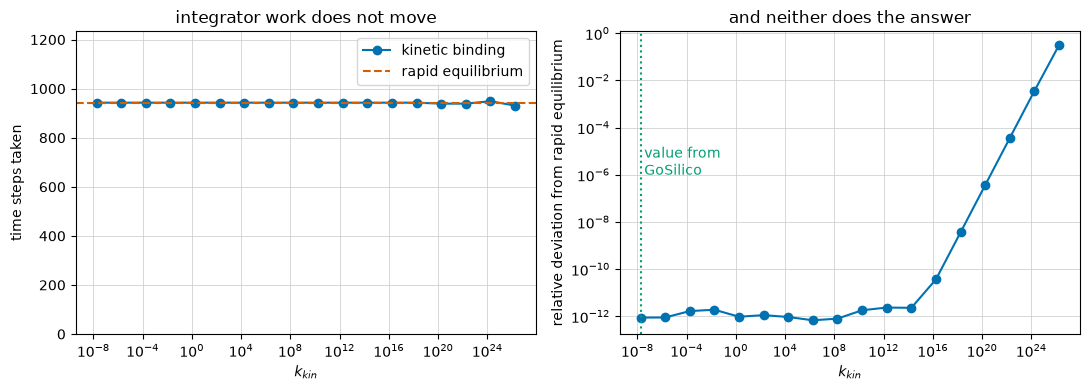

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

k_values = [row[0] for row in sweep]

axes[0].semilogx(k_values, [row[2].n_steps for row in sweep],
                 "o-", color=sm.COLORS[0], label="kinetic binding")
axes[0].axhline(reference.n_steps, ls="--", color=sm.COLORS[1],
                label="rapid equilibrium")
axes[0].set_xlabel(r"$k_{kin}$")
axes[0].set_ylabel("time steps taken")
axes[0].set_ylim(0, 1.3 * max(row[2].n_steps for row in sweep))
axes[0].set_title("integrator work does not move")
axes[0].legend()

axes[1].loglog(k_values, [max(row[3], 1e-16) for row in sweep],
               "o-", color=sm.COLORS[0])
axes[1].axvline(case.K_KIN, ls=":", color=sm.COLORS[2])
axes[1].text(case.K_KIN * 2, 1e-6, "value from\nGoSilico", color=sm.COLORS[2])
axes[1].set_xlabel(r"$k_{kin}$")
axes[1].set_ylabel("relative deviation from rapid equilibrium")
axes[1].set_title("and neither does the answer")

for axis in axes:
    axis.grid(True, color=sm.GRID_COLOR, lw=0.5)
figure.tight_layout()

The answer is a clean **no**, and it is worth being precise about why.

Over **34 orders of magnitude** of $k_{kin}$ the integrator takes the same
number of steps, at the same average BDF order, in the same wall-clock time.
The chromatogram is identical to the rapid-equilibrium solution until
$k_{kin} \approx 10^{24}$.

Two separate reasons:

1. **$k_d$ is not the rate.** The rate at which the binding relaxes is
   $k_d\,c_{salt}^{\,\nu}$, and with $\nu = 10.11$ the salt concentration
   contributes a factor of $10^{25}$ at the elution plateau. You have to push
   $k_d$ down to $10^{-25}$ before the binding is slow on the timescale of the
   chromatogram. Whatever $k_{kin}$ you plausibly write down, this system is in
   rapid equilibrium.
2. **A fast, stable mode is nearly free for an implicit integrator.** Once its
   transient has decayed, BDF does not have to resolve it; that is the whole
   point of using an implicit method. It costs at transients, and the
   transients here are the section transitions — which is exactly where the
   simulation broke.

So $k_{kin}$ is a *feasibility* knob in this case, not a performance knob: it
decides whether the residual can be evaluated in double precision, and nothing
else. That is an unusual and slightly uncomfortable thing for a model parameter
to be.

## 6. The actual answer: `IS_KINETIC = False`

If the binding is in rapid equilibrium for any sensible $k_{kin}$, then
$k_{kin}$ is not a physical parameter of this system at all. A value of
$1.8 \cdot 10^{-8}$ in GoSilico is best read as *"this is an equilibrium
model"*, which is also what was concluded in the thread.

In rapid equilibrium only the ratio $k_a / k_d$ enters, so the translation
problem disappears: set $k_a = k_{eq}$ and $k_d = 1$.

In [9]:
kinetic = simulate("kinetic_lean", consistent_init_mode=3)
equilibrium = simulate("equilibrium", is_kinetic=False,
                       sma_ka=case.K_EQ, sma_kd=1.0)

outlets = {label: outlet_of(label)[1]
           for label in ["kinetic_lean", "equilibrium"]}

times = t_out
difference = np.linalg.norm(
    outlets["kinetic_lean"][:, 1] - outlets["equilibrium"][:, 1]
) / np.linalg.norm(outlets["equilibrium"][:, 1])

print(f"kinetic (lean init)  : {kinetic.n_steps} steps, "
      f"{kinetic.compute_time:.2f} s")
print(f"rapid equilibrium    : {equilibrium.n_steps} steps, "
      f"{equilibrium.compute_time:.2f} s")
print(f"relative difference between the two chromatograms: {difference:.2e}")

kinetic (lean init)  : 943 steps, 0.20 s
rapid equilibrium    : 943 steps, 0.20 s
relative difference between the two chromatograms: 5.22e-13


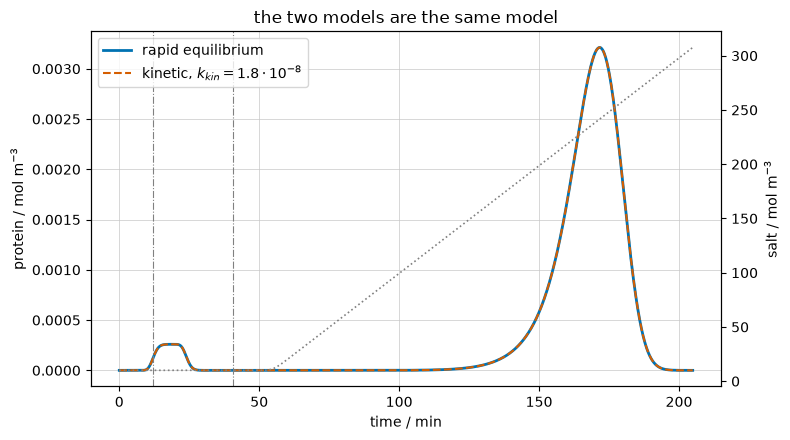

In [10]:
figure, axis = plt.subplots(figsize=(8, 4.5))
salt_axis = axis.twinx()

salt_axis.plot(times / 60, outlets["equilibrium"][:, 0], ":",
               color="grey", lw=1.2, label="salt")
axis.plot(times / 60, outlets["equilibrium"][:, 1],
          color=sm.COLORS[0], lw=2, label=r"rapid equilibrium")
axis.plot(times / 60, outlets["kinetic_lean"][:, 1], "--",
          color=sm.COLORS[1], lw=1.5,
          label=r"kinetic, $k_{kin} = 1.8 \cdot 10^{-8}$")

for boundary in [case.WASH_TIME, case.ELUTION_TIME]:
    axis.axvline(boundary / 60, color=sm.SECTION_COLOR, lw=0.8, ls="-.")

axis.set_xlabel("time / min")
axis.set_ylabel(r"protein / mol m$^{-3}$")
salt_axis.set_ylabel(r"salt / mol m$^{-3}$")
axis.set_title("the two models are the same model")
axis.legend(loc="upper left")
axis.grid(True, color=sm.GRID_COLOR, lw=0.5)
figure.tight_layout()

## What to take away

**The error message pointed at the time integrator; the fault was in the model
parameters.** `IDA_ERR_FAIL` with `h` at its minimum says "I cannot satisfy my
error test", not "your tolerances are too tight". Three of the four knobs one
would reach for first (`max_errtest_fail`, `max_newton_iter`, tightening
`abstol`) do nothing here, and the one that works, `init_step_size = 1e-15`,
works for a reason nobody would guess from the message.

**Ask what the rate constants are multiplied by.** In SMA the effective rates
are $k_a \bar{q}^{\,\nu}$ and $k_d c_{salt}^{\,\nu}$. With $\nu \approx 10$
those exponentials dominate completely, and the $k$'s on their own tell you
very little. Here they made two terms of order $10^{17}$ that had to cancel to
fifteen digits.

**A parameter that only exists in the other software's convention is a warning
sign.** $k_{kin} = 1.8 \cdot 10^{-8}$ was not measuring anything; it was
GoSilico's way of writing "equilibrium". Translating it literally produced a
model that is mathematically identical to the equilibrium one but numerically
unusable.

**Checklist that would have found this quickly**

1. Where does it fail? If the time is a section boundary, suspect the
   consistent initialization before anything else.
2. Does `CONSISTENT_INIT_MODE = 3` fix it? If yes, it is initialization, and
   you now know the differential time derivatives are the problem.
3. Evaluate the terms of your binding model at a realistic state by hand. If
   two of them are large and nearly equal, no solver setting will save you.
4. Does the answer change when you make the binding faster or slower? If not,
   the kinetics are not part of your model, whatever the parameter file says.